In [2]:
mono = adata[adata.obs["cell.type.coarse"] == "CD14 Monocyte"]
print(f"CD14 Monocyte subset: {mono.n_cells} cells, {mono.n_vars} genes")
print(f"Disease distribution: {mono.obs['disease'].value_counts().to_dict()}")
print(f"Donor distribution: {mono.obs['donor_id'].value_counts().to_dict()}")

AttributeError: 'AnnData' object has no attribute 'n_cells'

In [3]:
mono = adata[adata.obs["cell.type.coarse"] == "CD14 Monocyte"]
print(f"CD14 Monocyte subset: {mono.n_obs} cells, {mono.n_vars} genes")
print(f"Disease distribution: {mono.obs['disease'].value_counts().to_dict()}")
print(f"Donor distribution: {mono.obs['donor_id'].value_counts().to_dict()}")

CD14 Monocyte subset: 10339 cells, 24505 genes
Disease distribution: {'COVID-19': 8285, 'normal': 2054}
Donor distribution: {'C1': 3419, 'C7': 2095, 'C3': 1102, 'C4': 713, 'H1': 680, 'C5': 462, 'H5': 444, 'H2': 325, 'C6': 277, 'H6': 224, 'C2': 217, 'H3': 215, 'H4': 166}


In [4]:
# Step 2: Load Hallmark Interferon-alpha gene set
genes = load_geneset("MSigDB_Hallmark_2020", "Interferon alpha")
print(f"Hallmark Interferon-alpha gene set size: {len(genes)}")
print("Gene symbols:", genes[:10], "...")

# Step 3: Compute per-donor average expression scores
df = donor_scores(mono, genes, donor_col="donor_id", condition_col="disease", celltype_col=None, celltype=None)
print(f"Donor scores DataFrame shape: {df.shape}")
print(f"Condition distribution: {df['condition'].value_counts().to_dict()}")
print(f"Mean n_cells per donor: {df['n_cells'].mean():.1f}")

# Print score summary table (as required for plot)
print("Score summary by condition:")
print(df.groupby('condition')['score'].describe())

# Step 4: Test condition difference at donor level
stats = compare_groups(df, "score", "COVID-19", "normal")
print(f"Donors: n_case={stats['n_case']}, n_control={stats['n_control']}")
print(f"Mean score - COVID-19: {stats['mean_case']:.3f}, Normal: {stats['mean_control']:.3f}")
print(f"Mean diff: {stats['mean_diff']:.3f}, Cohen's d: {stats['cohens_d']:.3f}")
print(f"Welch p: {stats['welch_p']:.4f}, Mann-Whitney p: {stats['mannwhitney_p']:.4f}")

# Plot violin/stripchart of scores by condition
import matplotlib.pyplot as plt
import numpy as np

case_scores = df[df['condition']=='COVID-19']['score']
control_scores = df[df['condition']=='normal']['score']

plt.figure(figsize=(5,4))
plt.scatter([0]*len(case_scores), case_scores, alpha=0.5, color='red', label='COVID-19', s=10)
plt.scatter([1]*len(control_scores), control_scores, alpha=0.5, color='blue', label='Normal', s=10)
plt.xticks([0,1], ['COVID-19', 'Normal'])
plt.title("Interferon-alpha donor scores (CD14 Monocytes)")
plt.ylabel("Score (mean expression of Hallmark Interferon-alpha genes)")
plt.show()

# Multipletests across primary p-values (BH FDR correction)
from statsmodels.stats.multitest import multipletests
p_vals = [stats['welch_p'], stats['mannwhitney_p']]
rej, p_adj, _, _ = multipletests(p_vals, method='fdr_bh')
print(f"BH-adjusted p-values: Welch={p_adj[0]:.4f}, Mann-Whitney={p_adj[1]:.4f}")

# Key result
print(f"Key result: Adjusted p-value for Interferon-alpha response in CD14 monocytes: {min(p_adj):.4f}; Cohen's d: {stats['cohens_d']:.3f}")

KeyError: "'Interferon alpha' not in MSigDB_Hallmark_2020; try list_genesets('MSigDB_Hallmark_2020', contains=...)"

In [5]:
# List available Hallmark gene sets containing "Interferon"
lists = list_genesets("MSigDB_Hallmark_2020", contains="Interferon")
print("Available Interferon-related gene sets:")
for l in lists:
    print(f"  - {l}")

Available Interferon-related gene sets:
  - Interferon Alpha Response
  - Interferon Gamma Response


In [6]:
# Load Hallmark Interferon-alpha gene set
genes = load_geneset("MSigDB_Hallmark_2020", "Interferon Alpha Response")
# Compute per-donor average expression scores in CD14 monocytes
df = donor_scores(mono, genes, "donor_id", "disease")
print("Per-donor interferon-alpha response scores in CD14 Monocytes:")
print(df)
print(f"DataFrame shape: {df.shape}")
print(f"Condition distribution: {df['condition'].value_counts().to_dict()}")
print(f"Mean score per condition: {df.groupby('condition')['score'].mean().to_dict()}")

Gene set: 96/97 genes present (missing: ['TXNIP'])
      condition  n_cells  score
donor                          
C2     COVID-19      217 0.3786
C3     COVID-19     1102 0.3964
C7     COVID-19     2095 0.4300
C1     COVID-19     3419 0.6175
C4     COVID-19      713 0.6479
C5     COVID-19      462 0.7137
C6     COVID-19      277 0.7203
H6       normal      224 0.3419
H1       normal      680 0.3422
H4       normal      166 0.3597
H3       normal      215 0.3687
H2       normal      325 0.3721
H5       normal      444 0.4000
Per-donor interferon-alpha response scores in CD14 Monocytes:
      condition  n_cells     score
donor                             
C1     COVID-19     3419  0.617508
C2     COVID-19      217  0.378623
C3     COVID-19     1102  0.396375
C4     COVID-19      713  0.647945
C5     COVID-19      462  0.713723
C6     COVID-19      277  0.720255
C7     COVID-19     2095  0.429992
H1       normal      680  0.342239
H2       normal      325  0.372101
H3       normal      2

n_case=7, n_control=6, mean_case=0.5578, mean_control=0.3641, mean_diff=0.1937, cohens_d=1.721, welch_t=3.352, welch_p=0.01433, mannwhitney_u=40, mannwhitney_p=0.004662
compare_groups results:
  n_case: 7, n_control: 6
  mean_case: 0.5578, mean_control: 0.3641
  mean_diff: 0.1937
  cohens_d: 1.7212
  welch_t: 3.3518, welch_p: 0.014334
  mannwhitney_u: 40.0, mannwhitney_p: 0.004662


ValueError: The value for `inner` must be one of ['box', 'quart', 'stick', 'point', None], but 'strip' was passed.

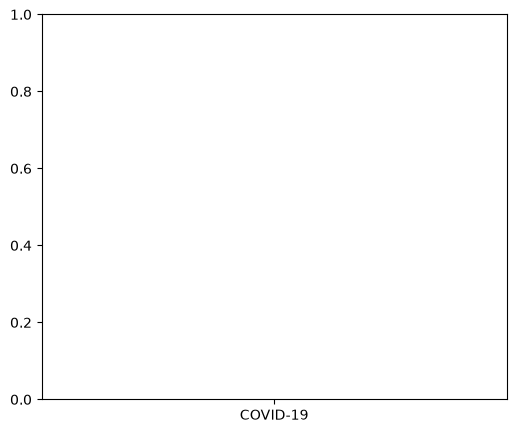

In [7]:
# Test condition difference at donor level
stats = compare_groups(df, "score", "COVID-19", "normal")
print("compare_groups results:")
print(f"  n_case: {stats['n_case']}, n_control: {stats['n_control']}")
print(f"  mean_case: {stats['mean_case']:.4f}, mean_control: {stats['mean_control']:.4f}")
print(f"  mean_diff: {stats['mean_diff']:.4f}")
print(f"  cohens_d: {stats['cohens_d']:.4f}")
print(f"  welch_t: {stats['welch_t']:.4f}, welch_p: {stats['welch_p']:.6f}")
print(f"  mannwhitney_u: {stats['mannwhitney_u']}, mannwhitney_p: {stats['mannwhitney_p']:.6f}")

# Violin/stripchart plot
plt.figure(figsize=(6, 5))
import seaborn as sns
sns.violinplot(data=df, x="condition", y="score", inner="strip", color="lightgray")
plt.title("Interferon-alpha response scores in CD14 Monocytes by Condition")
plt.xlabel("Condition")
plt.ylabel("Score (mean expression of ISG set)")
plt.show()

# Apply multipletests across primary p-values
# Since this is the first/hypothesis test, we have one primary p-value
# Using welch_p for multipletests correction
from statsmodels.stats.multitest import multipletests
pvals = [stats['welch_p']]
reject, p_adj, _, _ = multipletests(pvals, method='fdr_bh')
print(f"Multipletests adjusted p-value (FDR BH): {p_adj[0]:.6f}")
print(f"Reject null hypothesis: {reject[0]}")

n_case=7, n_control=6, mean_case=0.5578, mean_control=0.3641, mean_diff=0.1937, cohens_d=1.721, welch_t=3.352, welch_p=0.01433, mannwhitney_u=40, mannwhitney_p=0.004662
compare_groups results:
  n_case: 7, n_control: 6
  mean_case: 0.5578, mean_control: 0.3641
  mean_diff: 0.1937
  cohens_d: 1.7212
  welch_t: 3.3518, welch_p: 0.014334
  mannwhitney_u: 40.0, mannwhitney_p: 0.004662


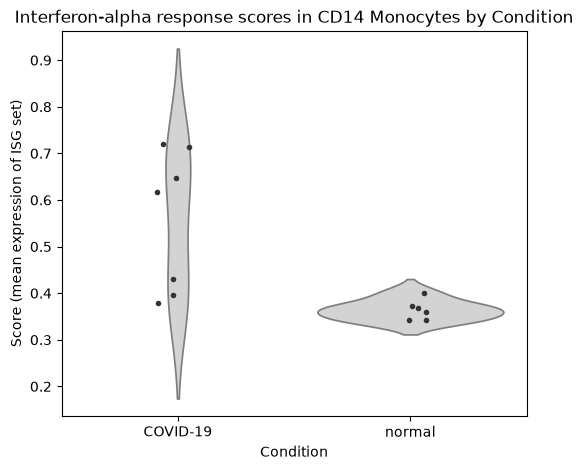

Multipletests adjusted p-value (FDR BH): 0.014334
Reject null hypothesis: True


In [8]:
# Test condition difference at donor level
stats = compare_groups(df, "score", "COVID-19", "normal")
print("compare_groups results:")
print(f"  n_case: {stats['n_case']}, n_control: {stats['n_control']}")
print(f"  mean_case: {stats['mean_case']:.4f}, mean_control: {stats['mean_control']:.4f}")
print(f"  mean_diff: {stats['mean_diff']:.4f}")
print(f"  cohens_d: {stats['cohens_d']:.4f}")
print(f"  welch_t: {stats['welch_t']:.4f}, welch_p: {stats['welch_p']:.6f}")
print(f"  mannwhitney_u: {stats['mannwhitney_u']}, mannwhitney_p: {stats['mannwhitney_p']:.6f}")

# Violin/stripchart plot
plt.figure(figsize=(6, 5))
sns.violinplot(data=df, x="condition", y="score", inner=None, color="lightgray")
sns.stripplot(data=df, x="condition", y="score", color="0.2", size=4, jitter=True)
plt.title("Interferon-alpha response scores in CD14 Monocytes by Condition")
plt.xlabel("Condition")
plt.ylabel("Score (mean expression of ISG set)")
plt.show()

# Apply multipletests across primary p-values
from statsmodels.stats.multitest import multipletests
pvals = [stats['welch_p']]
reject, p_adj, _, _ = multipletests(pvals, method='fdr_bh')
print(f"Multipletests adjusted p-value (FDR BH): {p_adj[0]:.6f}")
print(f"Reject null hypothesis: {reject[0]}")

In [9]:

import json as _json
_cond, _donor = 'disease', 'donor_id'
_skip = {_cond, _donor, 'cell.type.coarse'}
_obs = _ADATA.obs  # full dataset, even if a cell reassigned `adata`
_donors = _obs.groupby(_donor, observed=True)[_cond].first().astype(str)
_confounded = []
for _c in _obs.columns:
    if _c in _skip or _c.endswith("_ontology_term_id") or not 2 <= _obs[_c].nunique() <= 10:
        continue
    _per_donor = _obs.groupby(_donor, observed=True)[_c].agg(lambda s: s.astype(str).mode().iat[0])
    _tab = {k: set(v) for k, v in _per_donor.groupby(_donors)}
    # Confounded: each condition has one value of this column and the values differ.
    if all(len(v) == 1 for v in _tab.values()) and len(set().union(*_tab.values())) == len(_tab):
        _confounded.append(f"{_c}: " + ", ".join(f"{k}={next(iter(v))}" for k, v in _tab.items()))
print('__SCRAP_DESIGN__' + _json.dumps({"donors_per_condition": _donors.value_counts().to_dict(), "confounded": _confounded}))


__SCRAP_DESIGN__{"donors_per_condition": {"COVID-19": 7, "normal": 6}, "confounded": []}
